<a href="https://colab.research.google.com/github/MauveMoose/GameSalesAnalysis/blob/main/GameSalesAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/vgchartz-2024-expanded.csv', low_memory=False)

In [ ]:
df.head()

,img,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update,sales_source
0,/games/boxart/full_6510540AmericaFrontccc.jpg,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,20.32,6.37,0.99,9.85,3.12,2013-09-17,NaN,VGChartz (Original)
1,/games/boxart/full_5563178AmericaFrontccc.jpg,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,19.39,6.06,0.60,9.71,3.02,2014-11-18,2018-01-03,VGChartz (Original)
2,/games/boxart/827563ccc.jpg,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,16.15,8.41,0.47,5.49,1.78,2002-10-28,NaN,VGChartz (Original)
3,/games/boxart/full_9218923AmericaFrontccc.jpg,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,15.86,9.06,0.06,5.33,1.42,2013-09-17,NaN,VGChartz (Original)
4,/games/boxart/full_4990510AmericaFrontccc.jpg,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,15.09,6.18,0.41,6.05,2.44,2015-11-06,2018-01-14,VGChartz (Original)


In [ ]:
df['total_sales'].describe()


,total_sales
count,37636.000000
mean,0.462721
std,3.183667
min,0.000000
25%,0.020000
50%,0.060000
75%,0.250000
max,425.000000


In [ ]:
df['na_sales'].describe()


,na_sales
count,12637.000000
mean,0.264740
std,0.494787
min,0.000000
25%,0.050000
50%,0.120000
75%,0.280000
max,9.760000


In [ ]:
df['jp_sales'].describe()



,jp_sales
count,6726.000000
mean,0.102281
std,0.168811
min,0.000000
25%,0.020000
50%,0.040000
75%,0.120000
max,2.130000


In [ ]:
df['pal_sales'].describe()


,pal_sales
count,12824.000000
mean,0.149472
std,0.392653
min,0.000000
25%,0.010000
50%,0.040000
75%,0.140000
max,9.850000


In [ ]:
df['other_sales'].describe()

,other_sales
count,15128.000000
mean,0.043041
std,0.126643
min,0.000000
25%,0.000000
50%,0.010000
75%,0.030000
max,3.120000


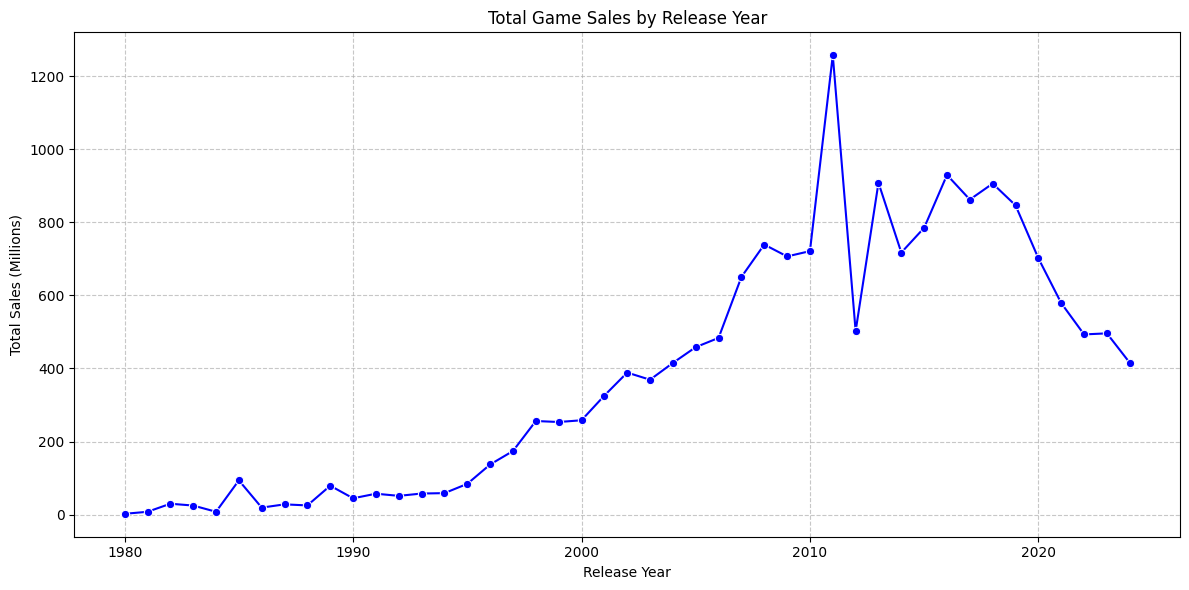

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure release_date is a datetime objects and extract the release year
df['release_year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year

# Group sales by release year
yearly_sales = df.groupby('release_year')['total_sales'].sum().reset_index()

# Filter out extreme future/past years if any data quality issues exist
yearly_sales = yearly_sales[(yearly_sales['release_year'] >= 1980) & (yearly_sales['release_year'] <= 2024)]

# Create the line plot
plt.figure(figsize=(12, 6))
sns.lineplot(data=yearly_sales, x='release_year', y='total_sales', marker='o', color='b')
plt.title('Total Game Sales by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Total Sales (Millions)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

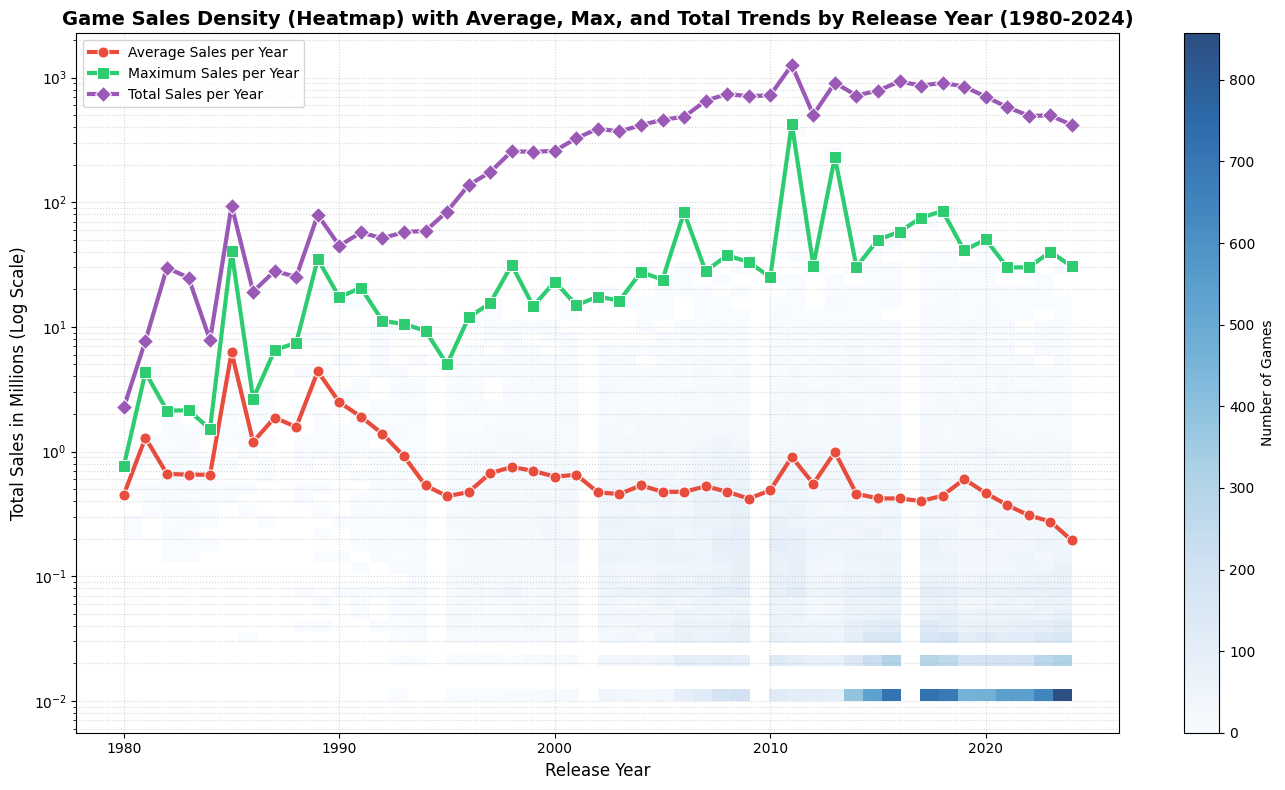

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure release_year column is extracted from release_date first
df['release_year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year

# Filter out missing years, extreme ranges, and non-positive sales to prevent log scale errors
plot_df = df[
    (df['release_year'] >= 1980) &
    (df['release_year'] <= 2024) &
    (df['total_sales'] > 0)
].dropna(subset=['total_sales'])

# Calculate average, maximum, and total sales by release year using the filtered data
yearly_metrics = plot_df.groupby('release_year')['total_sales'].agg(['mean', 'max', 'sum']).reset_index()

fig, ax = plt.subplots(figsize=(14, 8))

# Create a 2D density heatmap for individual game sales using histplot
sns.histplot(
    data=plot_df,
    x='release_year',
    y='total_sales',
    bins=50,
    log_scale=(False, True),
    cmap='Blues',
    cbar=True,
    cbar_kws={'label': 'Number of Games'},
    ax=ax,
    alpha=0.85
)

# Overlap the average sales line
sns.lineplot(
    data=yearly_metrics,
    x='release_year',
    y='mean',
    color='#e74c3c',
    linewidth=3,
    marker='o',
    markersize=8,
    label='Average Sales per Year',
    ax=ax
)

# Overlap the maximum sales line
sns.lineplot(
    data=yearly_metrics,
    x='release_year',
    y='max',
    color='#2ecc71',
    linewidth=3,
    marker='s',
    markersize=8,
    label='Maximum Sales per Year',
    ax=ax
)

# Overlap the total sales line
sns.lineplot(
    data=yearly_metrics,
    x='release_year',
    y='sum',
    color='#9b59b6',
    linewidth=3,
    marker='D',
    markersize=8,
    label='Total Sales per Year',
    ax=ax
)

plt.title('Game Sales Density (Heatmap) with Average, Max, and Total Trends by Release Year (1980-2024)', fontsize=14, fontweight='bold')
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Total Sales in Millions (Log Scale)', fontsize=12)
plt.grid(True, which='both', linestyle=':', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()